In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

In [ ]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
BASE_PATH = "/content/drive/MyDrive/hindi_dataset_kaggle/Indian Emotional Speech Corpora (IESC)"
BASE_PATH

'/content/drive/MyDrive/hindi_dataset_kaggle/Indian Emotional Speech Corpora (IESC)'

In [ ]:
SR = 16000
DURATION = 3
SAMPLES = SR * DURATION

In [ ]:
def load_audio(path):
    audio, _ = librosa.load(path, sr=SR, duration=DURATION)
    if len(audio) < SAMPLES:
        audio = np.pad(audio, (0, SAMPLES - len(audio)))
    return audio[:SAMPLES]


In [ ]:
# Audio Augmentation

def add_white_noise(audio, noise_factor=0.005):
    noise = np.random.randn(len(audio))
    return audio + noise_factor * noise

def time_shift(audio, shift_max=0.2):
    shift = int(np.random.uniform(-shift_max, shift_max) * len(audio))
    return np.roll(audio, shift)

def stretch_audio(audio, rate=0.8):
    stretched = librosa.effects.time_stretch(y=audio, rate=rate)
    if len(stretched) < SAMPLES:
        stretched = np.pad(stretched, (0, SAMPLES - len(stretched)))
    return stretched[:SAMPLES]

def pitch_shift_audio(audio, max_steps=4):
    steps = np.random.randint(-max_steps, max_steps)
    return librosa.effects.pitch_shift(y=audio, sr=SR, n_steps=steps)

In [ ]:
# MFCC feature extraction
def extract_mfcc(audio, n_mfcc=40):
    mfcc = librosa.feature.mfcc(y=audio, sr=SR, n_mfcc=n_mfcc)
    return np.mean(mfcc.T, axis=0)

In [ ]:
def extract_weighted_mfcc(audio, n_mfcc=40):
    mfcc = librosa.feature.mfcc(y=audio, sr=SR, n_mfcc=n_mfcc)


    weights = np.linspace(1, 2, mfcc.shape[1])

    weighted_mfcc = mfcc * weights
    return np.mean(weighted_mfcc.T, axis=0)


In [ ]:
X = []
y = []

label_map = {"angry": 0,"sad": 1,"happy": 2,"fear": 3}

for speaker in os.listdir(BASE_PATH):
    speaker_path = os.path.join(BASE_PATH, speaker)
    if not os.path.isdir(speaker_path):
        continue

    for emotion in os.listdir(speaker_path):
        emotion_path = os.path.join(speaker_path, emotion)
        emotion_lower = emotion.lower()

        if emotion_lower not in label_map:
            continue

        for file in os.listdir(emotion_path):
            if not file.lower().endswith(".wav"):
                continue

            full_path = os.path.join(emotion_path, file)
            audio = load_audio(full_path)
            label = label_map[emotion_lower]

            # Original
            X.append(extract_mfcc(audio))
            y.append(label)

            # Augmentations
            X.append(extract_mfcc(add_white_noise(audio)))
            y.append(label)

            X.append(extract_mfcc(time_shift(audio)))
            y.append(label)

            X.append(extract_mfcc(stretch_audio(audio)))
            y.append(label)

            X.append(extract_mfcc(pitch_shift_audio(audio)))
            y.append(label)

print("Total samples:", len(X))


Total samples: 2400


In [ ]:
mfcc_features = []
wmfcc_features = []
labels = []

for speaker in os.listdir(BASE_PATH):
    speaker_path = os.path.join(BASE_PATH, speaker)
    if not os.path.isdir(speaker_path):
        continue

    for emotion in os.listdir(speaker_path):
        emotion_path = os.path.join(speaker_path, emotion)
        emotion_lower = emotion.lower()

        if emotion_lower not in label_map:
            continue

        for file in os.listdir(emotion_path):
            if not file.lower().endswith(".wav"):
                continue

            full_path = os.path.join(emotion_path, file)
            audio = load_audio(full_path)
            label = label_map[emotion_lower]


            audios = [
                audio,
                add_white_noise(audio),
                time_shift(audio),
                stretch_audio(audio),
                pitch_shift_audio(audio)
            ]

            for a in audios:
                mfcc = extract_mfcc(a)
                wmfcc = extract_weighted_mfcc(a)

                mfcc_features.append(mfcc)
                wmfcc_features.append(wmfcc)
                labels.append(label)


In [ ]:
mfcc_df = pd.DataFrame(mfcc_features, columns=[f"MFCC_{i+1}" for i in range(40)])
wmfcc_df = pd.DataFrame(wmfcc_features, columns=[f"WMFCC_{i+1}" for i in range(40)])

label_df = pd.DataFrame(labels, columns=["Label"])
mfcc_df


,MFCC_1,MFCC_2,MFCC_3,MFCC_4,MFCC_5,MFCC_6,MFCC_7,MFCC_8,MFCC_9,MFCC_10,...,MFCC_31,MFCC_32,MFCC_33,MFCC_34,MFCC_35,MFCC_36,MFCC_37,MFCC_38,MFCC_39,MFCC_40
0,-522.008911,76.528816,32.841522,26.153269,8.554974,-5.495717,-17.269066,-1.614107,-2.119981,3.474005,...,-4.594275,-3.759914,-5.289618,-3.001740,-4.255848,1.579981,2.573889,6.761525,5.600183,7.141122
1,-281.551135,16.383156,13.264751,7.631651,3.437670,-1.646915,-3.259638,-2.571960,-3.251296,-1.508506,...,-2.454011,-1.945888,-1.755114,-1.388702,-0.261909,1.660339,3.137484,4.753224,5.804325,5.995769
2,-520.200195,76.920204,32.584419,26.370441,8.521692,-5.561231,-17.292070,-1.467881,-2.192444,3.380777,...,-4.718427,-3.827167,-5.211991,-2.995667,-4.276755,1.621393,2.670522,6.794843,5.551039,7.083400
3,-501.680695,90.052048,39.211681,31.332397,8.397218,-8.414512,-25.001560,-2.808096,-3.382861,4.227005,...,-6.223288,-4.652174,-5.725704,-3.722638,-4.759626,2.934723,4.403747,9.073937,7.066157,8.598115
4,-560.872253,98.013565,9.120193,49.250240,0.099125,28.878937,-23.186768,-0.164879,-16.657192,3.233432,...,-6.241233,-1.870503,-6.049807,-1.065327,-4.690620,-3.631198,-3.602660,-2.984099,-2.364290,-4.665282
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2395,-514.672058,111.611565,15.700950,25.770172,-13.559781,13.306591,-0.734328,-14.489922,9.412958,-4.185315,...,-2.393029,-1.871972,-2.623645,-1.353558,-3.153903,-3.704576,0.187295,-3.877387,-2.805647,-3.926632
2396,-260.077793,36.295550,16.570172,5.961485,-3.346096,-1.997218,-5.306823,-7.835346,-1.645338,-3.351559,...,-1.551729,-1.982524,-2.140028,-1.454927,-2.528997,-2.561815,-1.379567,-2.003758,-3.114809,-2.492776
2397,-515.086670,111.726212,15.811754,25.743494,-13.484801,13.439783,-0.650873,-14.358491,9.429570,-4.124791,...,-2.410249,-1.819395,-2.605835,-1.352920,-3.105142,-3.686282,0.202189,-3.857566,-2.849831,-3.989890
2398,-491.704010,132.629898,12.055294,28.127960,-22.192791,13.693297,-3.688764,-22.067390,9.653966,-6.749028,...,-2.888171,-1.591393,-2.904214,-0.671094,-4.235504,-4.936924,1.101016,-4.684195,-3.658582,-4.476275


In [ ]:
wmfcc_df

,WMFCC_1,WMFCC_2,WMFCC_3,WMFCC_4,WMFCC_5,WMFCC_6,WMFCC_7,WMFCC_8,WMFCC_9,WMFCC_10,...,WMFCC_31,WMFCC_32,WMFCC_33,WMFCC_34,WMFCC_35,WMFCC_36,WMFCC_37,WMFCC_38,WMFCC_39,WMFCC_40
0,-806.379801,111.822246,47.816612,38.867096,13.136221,-8.340188,-24.720346,-2.339591,-2.904724,4.841071,...,-6.477558,-5.672598,-7.602348,-4.575133,-6.145637,2.316795,3.796469,9.421590,7.961620,9.983472
1,-422.717822,23.790282,18.770779,11.014235,4.871475,-2.494718,-4.681863,-3.563423,-4.770725,-2.528281,...,-3.645645,-2.802139,-2.541202,-1.762178,-0.421407,2.315839,4.501112,6.724068,8.298647,8.562051
2,-769.764551,123.074879,51.697702,42.846584,14.076260,-9.575755,-27.642294,-2.491261,-3.515976,5.048834,...,-7.413265,-6.353371,-8.238070,-4.962319,-6.775940,2.707101,4.423411,10.558035,8.808502,11.051394
3,-755.630661,141.027184,60.457562,50.276276,12.841760,-14.535422,-39.244532,-4.446321,-5.286495,6.157850,...,-9.047978,-7.276495,-8.714696,-5.991895,-7.473183,4.487238,7.072666,13.630561,11.158596,13.115874
4,-862.969918,143.753379,13.760077,70.683887,2.791666,40.638517,-32.607573,-1.287696,-23.013217,4.209723,...,-8.829147,-2.790178,-8.325289,-1.386950,-6.562239,-5.362065,-4.928205,-4.316300,-3.633747,-6.666468
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2395,-800.691213,154.188979,24.190690,37.371354,-15.915149,19.609752,0.497957,-18.060848,13.374463,-5.102810,...,-3.245361,-2.709056,-3.591149,-1.770674,-4.230257,-4.928667,0.168540,-5.357741,-3.941875,-5.465891
2396,-396.850795,47.917638,22.164999,8.197619,-4.181669,-2.682551,-7.250215,-10.583636,-2.439466,-4.608983,...,-1.892590,-2.636176,-2.834063,-1.780195,-3.377173,-3.462899,-2.026621,-2.767743,-4.298072,-3.289058
2397,-774.250686,167.658031,23.929869,38.959035,-19.684125,20.167115,-0.867537,-21.140588,13.939103,-6.357465,...,-3.435224,-2.758461,-3.871848,-1.932484,-4.602607,-5.409760,0.289061,-5.798961,-4.286502,-6.007570
2398,-755.569702,191.165606,18.487333,41.689031,-30.245275,20.516981,-4.337997,-30.455525,13.867266,-9.754955,...,-4.018134,-2.463344,-4.192155,-0.822334,-5.949553,-6.855561,1.555149,-6.799273,-5.440168,-6.538704


In [ ]:
final_df = pd.concat([mfcc_df, wmfcc_df, label_df], axis=1)

excel_path = "/content/drive/MyDrive/mfcc_weighted_mfcc.xlsx"
final_df.to_excel(excel_path, index=False)

print("Excel file saved at:", excel_path)


Excel file saved at: /content/drive/MyDrive/mfcc_weighted_mfcc.xlsx


In [ ]:
mfcc_path = "/content/drive/MyDrive/mfcc_features.xlsx"
wmfcc_path = "/content/drive/MyDrive/weighted_mfcc_features.xlsx"
finalmfcc_df=pd.concat([mfcc_df,label_df],axis=1)
finalmfcc_df.to_excel(mfcc_path, index=False)
finalwmfcc_df=pd.concat([wmfcc_df,label_df],axis=1)
finalwmfcc_df.to_excel(wmfcc_path, index=False)

print("finalMFCC file saved at:", mfcc_path)
print("finalWeighted MFCC file saved at:", wmfcc_path)


finalMFCC file saved at: /content/drive/MyDrive/mfcc_features.xlsx
finalWeighted MFCC file saved at: /content/drive/MyDrive/weighted_mfcc_features.xlsx


In [ ]:
X = np.array(X)
y = np.array(y)


X = np.expand_dims(X, axis=2)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (2400, 40, 1, 1)
y shape: (2400,)


In [ ]:
X_mfcc = np.array(mfcc_features)
X_wmfcc = np.array(wmfcc_features)
y = np.array(labels)


X_mfcc = X_mfcc.reshape(X_mfcc.shape[0], 40, 1)
X_wmfcc = X_wmfcc.reshape(X_wmfcc.shape[0], 40, 1)


In [ ]:
def create_lstm_model():
    model = tf.keras.Sequential([tf.keras.layers.LSTM(128, input_shape=(40,1)),tf.keras.layers.Dropout(0.3),tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(5, activation='softmax')
    ])
    model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy']
    )
    return model

In [ ]:
def create_bilstm_model():
    model = tf.keras.Sequential([tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128),input_shape=(40,1)
        ),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(5, activation='softmax')
    ])
    model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy']
    )
    return model

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
emotion_labels = ["Angry", "Sad", "Happy", "Fear"]

In [ ]:
acc_lstm_mfcc = []
fold = 1
for train_idx, val_idx in skf.split(X_mfcc, y):
    print(f"===== Fold = {fold} =====")
    X_train, X_val = X_mfcc[train_idx], X_mfcc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    model = create_lstm_model()
    model.fit(X_train, y_train,validation_data=(X_val, y_val),epochs=50, batch_size=32, verbose=1)

    acc_lstm_mfcc.append(model.evaluate(X_val, y_val, verbose=0)[1])
    fold += 1

print("Avg Accuracy (LSTM + MFCC):", np.mean(acc_lstm_mfcc))


===== Fold = 1 =====
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.3406 - loss: 1.4393 - val_accuracy: 0.3750 - val_loss: 1.3166
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.4214 - loss: 1.2536 - val_accuracy: 0.4208 - val_loss: 1.2859
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.5031 - loss: 1.1630 - val_accuracy: 0.5146 - val_loss: 1.1549
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.5250 - loss: 1.0939 - val_accuracy: 0.5958 - val_loss: 0.9953
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.5936 - loss: 0.9484 - val_accuracy: 0.6125 - val_loss: 0.9757
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.6198 - loss: 0.8845 - val_accuracy: 0.6750 - val_loss: 0.8528
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.6873 - loss: 0.7910 - val_accuracy: 0.6875 - val_loss: 0.7479
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.7330 - loss: 0.6903 - val_accuracy: 0.7167 - val_loss: 0.

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.3630 - loss: 1.4353 - val_accuracy: 0.4708 - val_loss: 1.2240
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.4444 - loss: 1.2321 - val_accuracy: 0.5417 - val_loss: 1.1140
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.5039 - loss: 1.1260 - val_accuracy: 0.5437 - val_loss: 1.0826
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.5530 - loss: 1.0563 - val_accuracy: 0.6521 - val_loss: 0.9266
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.6199 - loss: 0.9072 - val_accuracy: 0.6479 - val_loss: 0.8291
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.6510 - loss: 0.8416 - val_accuracy: 0.7167 - val_loss: 0.7707
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.7186 - loss: 0.7281 - val_accuracy: 0.6875 - val_loss: 0.7656
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.7204 - loss: 0.6834 - val_accuracy: 0.7125 - val_loss: 0.

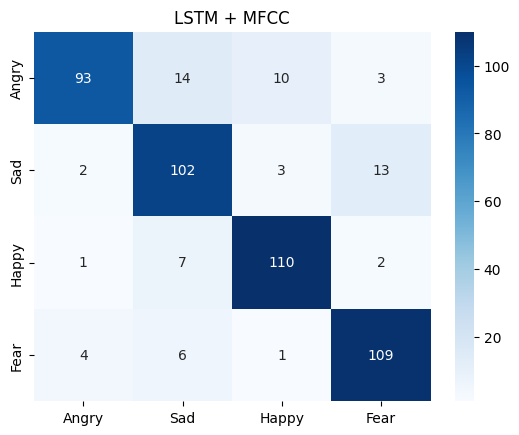


Classification Report 
               precision    recall  f1-score   support

       Angry       0.93      0.78      0.85       120
         Sad       0.79      0.85      0.82       120
       Happy       0.89      0.92      0.90       120
        Fear       0.86      0.91      0.88       120

    accuracy                           0.86       480
   macro avg       0.87      0.86      0.86       480
weighted avg       0.87      0.86      0.86       480



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_mfcc, y, test_size=0.2, stratify=y, random_state=42
)

model = create_lstm_model()
model.fit(X_train, y_train,
          validation_data=(X_test, y_test),
          epochs=50, batch_size=32, verbose=1)

y_pred = np.argmax(model.predict(X_test), axis=1)

sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt="d",
            xticklabels=emotion_labels,
            yticklabels=emotion_labels,
            cmap="Blues")
plt.title("LSTM + MFCC")
plt.show()

print("\nClassification Report \n",classification_report(y_test, y_pred, target_names=emotion_labels))



===== Fold = 1 (Bi-LSTM + MFCC) =====
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - accuracy: 0.3420 - loss: 1.4089 - val_accuracy: 0.4500 - val_loss: 1.2536
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - accuracy: 0.4699 - loss: 1.1831 - val_accuracy: 0.5583 - val_loss: 1.0971
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 106ms/step - accuracy: 0.5742 - loss: 1.0034 - val_accuracy: 0.6438 - val_loss: 0.8626
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.6536 - loss: 0.8505 - val_accuracy: 0.7354 - val_loss: 0.7175
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.7225 - loss: 0.6825 - val_accuracy: 0.7479 - val_loss: 0.6261
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 160ms/step - accuracy: 0.7917 - loss: 0.5595 - val_accuracy: 0.7250 - val_loss: 0.6594
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - accuracy: 0.7918 - loss: 0.5597 - val_accuracy: 0.7896 - val_loss: 0.5168
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 134ms/step - accuracy: 0.8405 - loss: 0.4461 - val_accuracy: 0.8167 - val_l

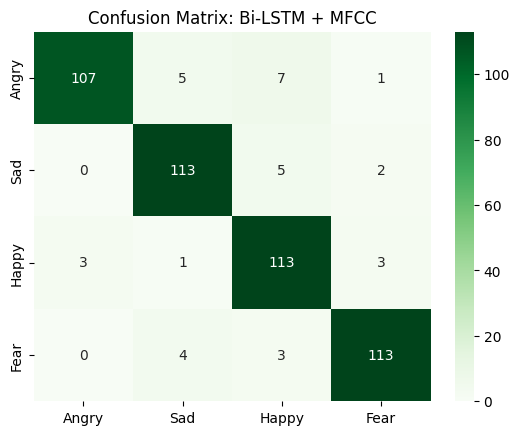


Classification Report (Bi-LSTM + MFCC):

              precision    recall  f1-score   support

       Angry       0.97      0.89      0.93       120
         Sad       0.92      0.94      0.93       120
       Happy       0.88      0.94      0.91       120
        Fear       0.95      0.94      0.95       120

    accuracy                           0.93       480
   macro avg       0.93      0.93      0.93       480
weighted avg       0.93      0.93      0.93       480



In [ ]:
fold = 1
acc_bilstm_mfcc = []

for train_idx, val_idx in skf.split(X_mfcc, y):

    print(f"\n===== Fold = {fold} (Bi-LSTM + MFCC) =====")

    X_train, X_val = X_mfcc[train_idx], X_mfcc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    model = create_bilstm_model()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        verbose=1
    )

    loss, acc = model.evaluate(X_val, y_val, verbose=0)
    acc_bilstm_mfcc.append(acc)

    print(f"Fold={fold} Accuracy =  {acc:.4f}")

    fold += 1

y_pred = np.argmax(model.predict(X_val), axis=1)

cm = confusion_matrix(y_val, y_pred)

sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=emotion_labels,
            yticklabels=emotion_labels,
            cmap="Greens")

plt.title("Confusion Matrix: Bi-LSTM + MFCC")
plt.show()

print("\nClassification Report (Bi-LSTM + MFCC):\n")
print(classification_report(y_val, y_pred, target_names=emotion_labels))



===== Fold = 1 (LSTM + Weighted MFCC) =====
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.3221 - loss: 1.4330 - val_accuracy: 0.4271 - val_loss: 1.2996
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.4384 - loss: 1.2263 - val_accuracy: 0.4896 - val_loss: 1.1496
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.5149 - loss: 1.1144 - val_accuracy: 0.5521 - val_loss: 1.0709
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.5565 - loss: 1.0238 - val_accuracy: 0.6250 - val_loss: 0.9611
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.6223 - loss: 0.8986 - val_accuracy: 0.5917 - val_loss: 0.9742
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.6216 - loss: 0.9064 - val_accuracy: 0.6562 - val_loss: 0.8613
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.6506 - loss: 0.8302 - val_accuracy: 0.6750 - val_loss: 0.8060
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.6969 - loss: 0.7551 - val_accuracy: 0.6854 - val_loss: 0.

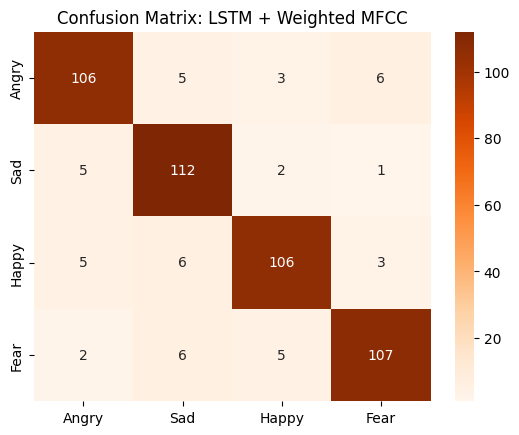


Classification Report (LSTM + Weighted MFCC):

              precision    recall  f1-score   support

       Angry       0.90      0.88      0.89       120
         Sad       0.87      0.93      0.90       120
       Happy       0.91      0.88      0.90       120
        Fear       0.91      0.89      0.90       120

    accuracy                           0.90       480
   macro avg       0.90      0.90      0.90       480
weighted avg       0.90      0.90      0.90       480



In [ ]:
fold = 1
acc_lstm_wmfcc = []

for train_idx, val_idx in skf.split(X_wmfcc, y):

    print(f"\n===== Fold = {fold} (LSTM + Weighted MFCC) =====")

    X_train, X_val = X_wmfcc[train_idx], X_wmfcc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    model = create_lstm_model()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        verbose=1
    )

    loss, acc = model.evaluate(X_val, y_val, verbose=0)
    acc_lstm_wmfcc.append(acc)

    print(f"Fold {fold} Accuracy: {acc:.4f}")

    fold += 1

y_pred = np.argmax(model.predict(X_val), axis=1)

cm = confusion_matrix(y_val, y_pred)

sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=emotion_labels,
            yticklabels=emotion_labels,
            cmap="Oranges")

plt.title("Confusion Matrix: LSTM + Weighted MFCC")
plt.show()

print("\nClassification Report (LSTM + Weighted MFCC):\n")
print(classification_report(y_val, y_pred, target_names=emotion_labels))



===== Fold = 1 (Bi-LSTM + Weighted MFCC) =====


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.2841 - loss: 1.4947 - val_accuracy: 0.4667 - val_loss: 1.2609
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - accuracy: 0.4571 - loss: 1.2159 - val_accuracy: 0.5146 - val_loss: 1.1342
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.5641 - loss: 1.0569 - val_accuracy: 0.6125 - val_loss: 0.9681
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.6467 - loss: 0.8574 - val_accuracy: 0.6687 - val_loss: 0.8663
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - accuracy: 0.7278 - loss: 0.7137 - val_accuracy: 0.6646 - val_loss: 0.7875
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.7437 - loss: 0.6791 - val_accuracy: 0.7667 - val_loss: 0.6174
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.7855 - loss: 0.5712 - val_accuracy: 0.7896 - val_loss: 0.5603
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step - accuracy: 0.8128 - loss: 0.5232 - val_accuracy: 0.7792

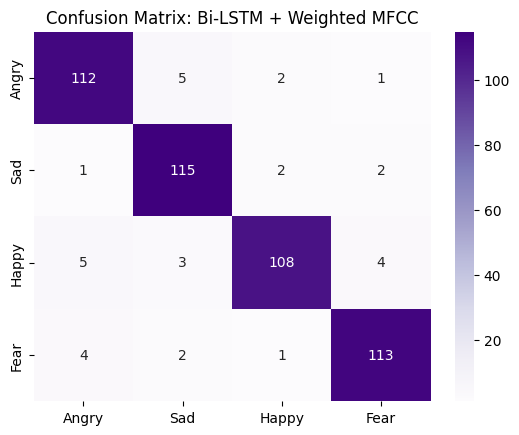


Classification Report (Bi-LSTM + Weighted MFCC):

              precision    recall  f1-score   support

       Angry       0.92      0.93      0.93       120
         Sad       0.92      0.96      0.94       120
       Happy       0.96      0.90      0.93       120
        Fear       0.94      0.94      0.94       120

    accuracy                           0.93       480
   macro avg       0.93      0.93      0.93       480
weighted avg       0.93      0.93      0.93       480



In [ ]:
fold = 1
acc_bilstm_wmfcc = []

for train_idx, val_idx in skf.split(X_wmfcc, y):

    print(f"\n===== Fold = {fold} (Bi-LSTM + Weighted MFCC) =====")

    X_train, X_val = X_wmfcc[train_idx], X_wmfcc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    model = create_bilstm_model()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        verbose=1
    )

    loss, acc = model.evaluate(X_val, y_val, verbose=0)
    acc_bilstm_wmfcc.append(acc)

    print(f"Fold {fold} Accuracy: {acc:.4f}")

    fold += 1

y_pred = np.argmax(model.predict(X_val), axis=1)

cm = confusion_matrix(y_val, y_pred)

sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=emotion_labels,
            yticklabels=emotion_labels,
            cmap="Purples")

plt.title("Confusion Matrix: Bi-LSTM + Weighted MFCC")
plt.show()

print("\nClassification Report (Bi-LSTM + Weighted MFCC):\n")
print(classification_report(y_val, y_pred, target_names=emotion_labels))


In [ ]:
print("\n===== Average Accuracies =====")
print("LSTM + MFCC          :", np.mean(acc_lstm_mfcc))
print("Bi-LSTM + MFCC       :", np.mean(acc_bilstm_mfcc))
print("LSTM + Weighted MFCC :", np.mean(acc_lstm_wmfcc))
print("Bi-LSTM + Weighted MFCC:", np.mean(acc_bilstm_wmfcc))



===== Average Accuracies =====
LSTM + MFCC          : 0.9041666626930237
Bi-LSTM + MFCC       : 0.9270833253860473
LSTM + Weighted MFCC : 0.89041668176651
Bi-LSTM + Weighted MFCC: 0.9125


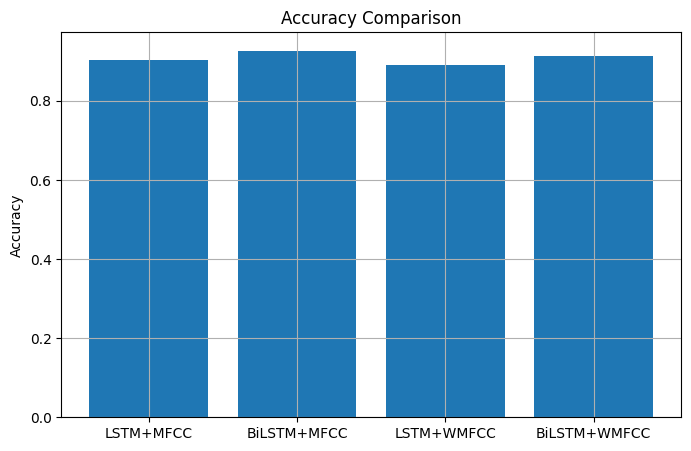

In [ ]:
models = [
    "LSTM+MFCC",
    "BiLSTM+MFCC",
    "LSTM+WMFCC",
    "BiLSTM+WMFCC"
]

accuracies = [
    np.mean(acc_lstm_mfcc),
    np.mean(acc_bilstm_mfcc),
    np.mean(acc_lstm_wmfcc),
    np.mean(acc_bilstm_wmfcc)
]

plt.figure(figsize=(8,5))
plt.bar(models, accuracies)
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.grid(True)


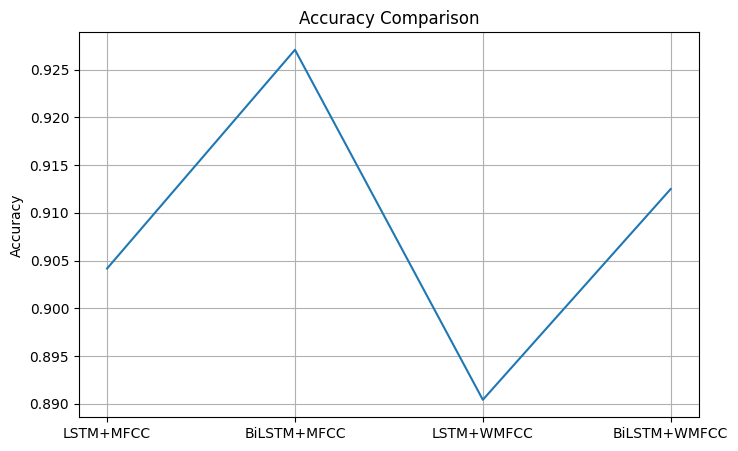

In [ ]:
models = [
    "LSTM+MFCC",
    "BiLSTM+MFCC",
    "LSTM+WMFCC",
    "BiLSTM+WMFCC"
]

accuracies = [
    np.mean(acc_lstm_mfcc),
    np.mean(acc_bilstm_mfcc),
    np.mean(acc_lstm_wmfcc),
    np.mean(acc_bilstm_wmfcc)
]

plt.figure(figsize=(8,5))
plt.plot(models, accuracies)
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.grid(True)


/tmp/ipython-input-3259112259.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


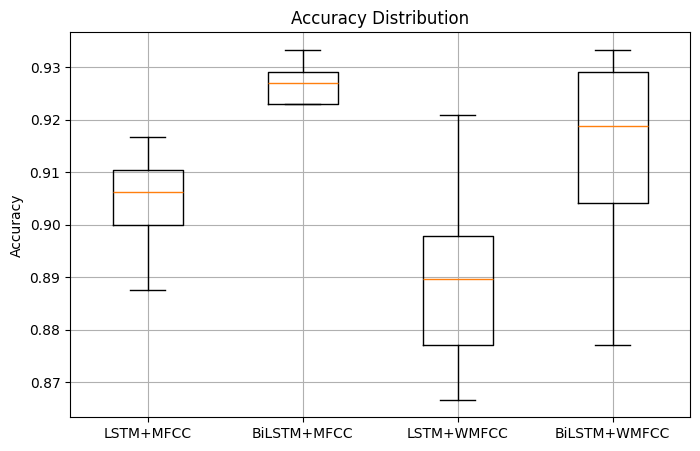

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot(
    [acc_lstm_mfcc, acc_bilstm_mfcc, acc_lstm_wmfcc, acc_bilstm_wmfcc],
    labels=models
)

plt.ylabel("Accuracy")
plt.title("Accuracy Distribution")
plt.grid(True)




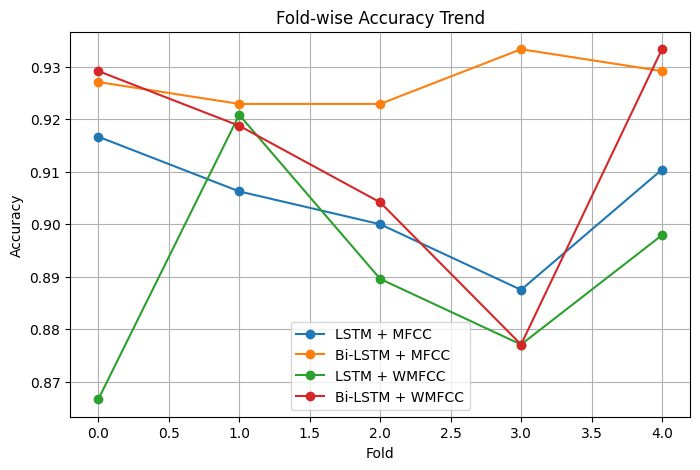

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(acc_lstm_mfcc, marker='o', label='LSTM + MFCC')
plt.plot(acc_bilstm_mfcc, marker='o', label='Bi-LSTM + MFCC')
plt.plot(acc_lstm_wmfcc, marker='o', label='LSTM + WMFCC')
plt.plot(acc_bilstm_wmfcc, marker='o', label='Bi-LSTM + WMFCC')

plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Fold-wise Accuracy Trend")
plt.legend()
plt.grid(True)

